# 4a. Attention by hand: is this WXZ a true start?

A static embedding gives the initiator `WXZ` **one** vector, whether it starts a gene or not (prediction S4 in
notebook 03b). Here we build the smallest model that can tell the difference: **one attention head**, written in
NumPy with every tensor visible and every gradient derived by hand.

The task, on short transcripts (RNA spelling, so the initiator is written `WXV`): **is this `WXV` a true
start?** It is one only if an intact ribosome-binding site `WXX WXX` sits 2–5 positions upstream.

| Category | What is in front of (or around) `WXV` | Label |
|---|---|---|
| `true_start` | intact RBS, gap of 1–3 codons | 1 |
| `broken_rbs` | RBS with one base mutated | 0 |
| `no_rbs` | no RBS at all | 0 |
| `misplaced_rbs` | an intact RBS at the wrong place: 6–8 positions upstream, or downstream of the start | 0 |

The last category makes **position** matter: an intact RBS *somewhere* is not enough. We train two models —
with and without positional embeddings — and test a prediction fixed in design-spec §4.6 before training:

> On test sequences, the model **with** positions reaches ≥ 0.90 accuracy on `misplaced_rbs`, and the model
> **without** positions reaches ≤ 0.50 on them.

Lab B runs exactly the same maths in JavaScript, live.

*Run from `04-attention/`.*

In [1]:
import sys, os, json, inspect
from datetime import datetime, timezone
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "..")
import protocell_lang as L

# ------------------------------------------------------------
# Configuration (design-spec §4.6)
# ------------------------------------------------------------
SEED = 42
D = 4                    # embedding size
MAX_LEN = 14             # longest mini-transcript
N_TRAIN, N_TEST = 600, 300
INIT_STD = 0.5
LEARNING_RATE = 0.1
STEPS = 3000
CATEGORIES = ["true_start", "broken_rbs", "no_rbs", "misplaced_rbs"]
CATEGORY_P = [1 / 2, 1 / 6, 1 / 6, 1 / 6]

OUTPUT_FILE = "../data/web/mini-transcripts.json"
NOTEBOOK = "04-attention/04a_attention_by_hand.ipynb"

## 1. The mini-transcripts

Every token comes from `protocell_lang`. Spacer and gap codons are drawn from the RNA codons **except** the
initiator `WXV`, the RBS codon `WXX` and the gene markers, so the only `WXV` is the one we classify and an RBS
appears only where we put it. After `WXV` come a gene marker and 1–4 body codons in that gene's dialect, as in
a real gene block.

In [2]:
INITIATOR = L.transcribe(L.INITIATOR)                     # WXV
RBS = [L.transcribe(c) for c in L.RBS]                    # WXX WXX
VOCABULARY = [L.transcribe(c) for c in L.ALL_CODONS]      # the 64 RNA codons
TOKEN_ID = {c: i for i, c in enumerate(VOCABULARY)}
MARKER_RNA = {g["name"]: L.transcribe(g["marker"]) for g in L.GENES}
SPACER_CODONS = [c for c in VOCABULARY if c not in {INITIATOR, RBS[0]} and c not in MARKER_RNA.values()]
RBS_MUTANTS = ["XXX", "YXX", "VXX", "WXW"]                # one-base mutations of WXX (design-spec §2.4)


def make_mini_transcript(category, rng):
    gene = L.GENES[rng.integers(len(L.GENES))]
    distribution = L.codon_distribution(gene)
    spacer = lambda n: [SPACER_CODONS[i] for i in rng.integers(len(SPACER_CODONS), size=n)]
    variant = ["upstream", "downstream"][rng.integers(2)] if category == "misplaced_rbs" else None

    gap = int(rng.integers(5, 8)) if variant == "upstream" else int(rng.integers(1, 4))
    n_body = int(rng.integers(1, 5))
    if variant == "upstream":
        n_body = min(n_body, MAX_LEN - (2 + gap + 2))
    body = [L.transcribe(c) for c in rng.choice(L.CODING_CODONS, size=n_body, p=list(distribution.values()))]

    if category in ("true_start", "broken_rbs") or variant == "upstream":
        cue = list(RBS)
        if category == "broken_rbs":
            cue[rng.integers(2)] = RBS_MUTANTS[rng.integers(len(RBS_MUTANTS))]
    else:
        cue = spacer(2)                                   # no RBS in front of the start
    tokens = cue + spacer(gap) + [INITIATOR, MARKER_RNA[gene["name"]]]
    if variant == "downstream":
        at = int(rng.integers(len(body) + 1))
        body = body[:at] + list(RBS) + body[at:]
    tokens = (tokens + body)[:MAX_LEN]
    n_lead = int(rng.integers(max(0, 8 - len(tokens)), MAX_LEN - len(tokens) + 1))
    tokens = spacer(n_lead) + tokens
    return {"tokens": tokens, "target": tokens.index(INITIATOR), "label": int(category == "true_start"),
            "category": str(category), "variant": variant}


def make_dataset(n, rng):
    return [make_mini_transcript(c, rng) for c in rng.choice(CATEGORIES, size=n, p=CATEGORY_P)]


rng = np.random.default_rng(SEED)
train = make_dataset(N_TRAIN, rng)
test = make_dataset(N_TEST, rng)

counts = pd.DataFrame({"train": Counter(e["category"] for e in train), "test": Counter(e["category"] for e in test)})
print("Lengths:", sorted(Counter(len(e["tokens"]) for e in train + test).items()))
counts

Lengths: [(8, 52), (9, 100), (10, 127), (11, 138), (12, 143), (13, 154), (14, 186)]


,train,test
no_rbs,102,39
true_start,300,159
misplaced_rbs,92,50
broken_rbs,106,52


In [3]:
def show(example):
    marks = []
    for i, c in enumerate(example["tokens"]):
        marks.append(f"[{c}]" if i == example["target"] else c)
    print(f"{example['category']:14} {example['variant'] or '':10} label {example['label']}:  {' '.join(marks)}")


for category in CATEGORIES:
    for e in [e for e in train if e["category"] == category][:2]:
        show(e)

true_start                label 1:  VWX VVY VWY WXX WXX YWX XWX XYW [WXV] WYX XVY XXX YXX YYX
true_start                label 1:  VWX VWX XVY VXX WXX WXX WXW WWW [WXV] WWX XVY YVY YXX YVX
broken_rbs                label 0:  VXW XXX WXX YXV [WXV] WWX XYX XWX YVX XYX
broken_rbs                label 0:  WVV YYV XVY VWV WYW XXX WXX WXW [WXV] WWX XVX XVX XYX
no_rbs                    label 0:  VWY YWY VYW WYV [WXV] WVY YWX YWX YYX YWX
no_rbs                    label 0:  XXV VYV YWX VXY XXY WXW VXW XXX YXV YXY [WXV] WWY XWY
misplaced_rbs  upstream   label 0:  VYW YWY XYY VVY WXX WXX YXW VWV VVX YWV VYX [WXV] WYY XWY
misplaced_rbs  upstream   label 0:  YXY WWV WXX WXX XXX VYW YWX WWW VVX YXX XXV [WXV] WXY XYX


## 2. The model

Each sequence of $n$ tokens becomes a matrix $X$ ($n \times 4$): row $i$ is the token's embedding plus, when
positions are on, the embedding of position $i$:

$$X = E[\text{tokens}] + P[0{:}n].$$

One attention head:

$$Q = XW_Q,\quad K = XW_K,\quad V = XW_V,\qquad S = \frac{QK^\top}{\sqrt d},\qquad A = \mathrm{softmax}_{\text{rows}}(S),\qquad H = AV.$$

Row $i$ of $A$ says how much token $i$ looks at every token; row $i$ of $H$ is the weighted average of the value
vectors. We read out only row $t$, the `WXV` token, and classify it with logistic regression:

$$h = H_t,\qquad z = w\cdot h + b,\qquad p = \sigma(z) = P(\text{true start}).$$

No biases in $Q, K, V$, no residual connection, no layer normalisation: every number in the model is one of
the tensors above.

In [4]:
def init_params(seed=SEED):
    rng = np.random.default_rng(seed)
    return {"E": rng.normal(0, INIT_STD, (len(VOCABULARY), D)),     # token embeddings
            "P": rng.normal(0, INIT_STD, (MAX_LEN, D)),             # position embeddings
            "W_Q": rng.normal(0, INIT_STD, (D, D)),
            "W_K": rng.normal(0, INIT_STD, (D, D)),
            "W_V": rng.normal(0, INIT_STD, (D, D)),
            "w": rng.normal(0, INIT_STD, D),                         # classifier weights
            "b": np.zeros(())}                                       # classifier bias


def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def forward(params, tokens, target, use_position=True):
    ids = [TOKEN_ID[c] for c in tokens]
    X = params["E"][ids] + (params["P"][:len(ids)] if use_position else 0)
    Q, K, V = X @ params["W_Q"], X @ params["W_K"], X @ params["W_V"]
    S = Q @ K.T / np.sqrt(D)
    A = np.exp(S - S.max(axis=1, keepdims=True))
    A = A / A.sum(axis=1, keepdims=True)
    H = A @ V
    h = H[target]
    z = h @ params["w"] + params["b"]
    return {"X": X, "Q": Q, "K": K, "V": V, "S": S, "A": A, "H": H, "h": h, "z": float(z), "p": float(sigmoid(z))}


example = train[0]
show(example)
result = forward(init_params(), example["tokens"], example["target"])
print("\nAttention weights of the WXV row (untrained model):", np.round(result["A"][example["target"]], 3))
print("p(true start) =", round(result["p"], 3))

no_rbs                    label 0:  VWY YWY VYW WYV [WXV] WVY YWX YWX YYX YWX

Attention weights of the WXV row (untrained model): [0.126 0.066 0.083 0.08  0.171 0.051 0.116 0.082 0.093 0.131]
p(true start) = 0.483


## 3. Gradients by hand

Training uses all sequences at once (full batch). Sequences have different lengths, so they are padded to 14
tokens and a **mask** stops anything from attending to the padding. Only the `WXV` row of attention is needed
for the loss, so the training code computes just that row: query $q = x_t W_Q$, scores $s_j = q\cdot k_j/\sqrt d$,
weights $a = \mathrm{softmax}(s)$, output $h = \sum_j a_j v_j$.

The loss is the mean binary cross-entropy over the $N$ sequences. Going backwards, one step at a time:

| Quantity | Gradient |
|---|---|
| logit $z$ | $\partial \ell/\partial z = (p - y)/N$ |
| classifier | $\partial w = h\,\partial z$, $\;\partial b = \partial z$ |
| readout $h$ | $\partial h = \partial z\, w$ |
| values | $\partial v_j = a_j\,\partial h$ |
| weights | $\partial a_j = v_j\cdot\partial h$ |
| scores (softmax Jacobian) | $\partial s_j = a_j\big(\partial a_j - \sum_k a_k\,\partial a_k\big)$ |
| query and keys | $\partial q = \sum_j \partial s_j\,k_j/\sqrt d$, $\;\partial k_j = \partial s_j\, q/\sqrt d$ |
| projections | $\partial W_Q = x_t^\top \partial q$, $\;\partial W_K = \sum_j x_j^\top \partial k_j$, $\;\partial W_V = \sum_j x_j^\top \partial v_j$ |
| inputs | $\partial x_j = \partial k_j W_K^\top + \partial v_j W_V^\top$ (+ $\partial q\, W_Q^\top$ for $j = t$) |
| embeddings | each $\partial x_j$ is added to its token's row of $E$ and, with positions, to row $j$ of $P$ |

In [5]:
def batch_arrays(dataset):
    n = len(dataset)
    ids = np.zeros((n, MAX_LEN), dtype=int)
    mask = np.zeros((n, MAX_LEN), dtype=bool)
    for i, ex in enumerate(dataset):
        ids[i, :len(ex["tokens"])] = [TOKEN_ID[c] for c in ex["tokens"]]
        mask[i, :len(ex["tokens"])] = True
    target = np.array([ex["target"] for ex in dataset])
    label = np.array([ex["label"] for ex in dataset], dtype=float)
    return ids, mask, target, label


def forward_backward(params, batch, use_position=True):
    ids, mask, t, y = batch
    n = len(ids)
    rows = np.arange(n)
    X = params["E"][ids] + (params["P"][None, :] if use_position else 0)     # (n, 14, d)
    xt = X[rows, t]                                                          # the WXV rows
    q = xt @ params["W_Q"]
    K = X @ params["W_K"]
    V = X @ params["W_V"]
    s = np.einsum("nd,nld->nl", q, K) / np.sqrt(D)
    s = np.where(mask, s, -np.inf)                                           # padding gets no attention
    a = np.exp(s - s.max(axis=1, keepdims=True))
    a = a / a.sum(axis=1, keepdims=True)
    h = np.einsum("nl,nld->nd", a, V)
    z = h @ params["w"] + params["b"]
    p = sigmoid(z)
    loss = float(np.mean(np.logaddexp(0, -z) * y + np.logaddexp(0, z) * (1 - y)))

    dz = (p - y) / n
    grads = {"w": h.T @ dz, "b": np.sum(dz)}
    dh = dz[:, None] * params["w"][None, :]
    dV = a[:, :, None] * dh[:, None, :]
    da = np.einsum("nld,nd->nl", V, dh)
    ds = a * (da - np.sum(a * da, axis=1, keepdims=True))                    # softmax Jacobian
    dq = np.einsum("nl,nld->nd", ds, K) / np.sqrt(D)
    dK = ds[:, :, None] * q[:, None, :] / np.sqrt(D)
    grads["W_Q"] = xt.T @ dq
    grads["W_K"] = np.einsum("nld,nle->de", X, dK)
    grads["W_V"] = np.einsum("nld,nle->de", X, dV)
    dX = dK @ params["W_K"].T + dV @ params["W_V"].T
    dX[rows, t] += dq @ params["W_Q"].T
    dX = dX * mask[:, :, None]
    grads["E"] = np.zeros_like(params["E"])
    np.add.at(grads["E"], ids[mask], dX[mask])
    grads["P"] = dX.sum(axis=0) if use_position else np.zeros_like(params["P"])
    return loss, z, a, grads

### Two checks before training

1. The batched code and the one-sequence `forward` must give the same logit.
2. **Gradient check:** nudge every parameter by ±ε and compare the change of the loss with the analytic
   gradient (central differences, ε = 1e-5). It passes when the relative error is below 1e-5.

In [6]:
params0 = init_params()
_, z_batch, _, _ = forward_backward(params0, batch_arrays(train[:20]))
z_single = [forward(params0, e["tokens"], e["target"])["z"] for e in train[:20]]
print("max |batched − single-sequence| logit:", np.max(np.abs(z_batch - z_single)))


def gradient_check(params, dataset, use_position, epsilon=1e-5):
    batch = batch_arrays(dataset)
    grads = forward_backward(params, batch, use_position)[3]
    worst = 0.0
    for name, value in params.items():
        flat, analytic = value.reshape(-1), np.reshape(grads[name], -1)
        for i in range(flat.size):
            original = flat[i]
            flat[i] = original + epsilon
            plus = forward_backward(params, batch, use_position)[0]
            flat[i] = original - epsilon
            minus = forward_backward(params, batch, use_position)[0]
            flat[i] = original
            numeric = (plus - minus) / (2 * epsilon)
            worst = max(worst, abs(numeric - analytic[i]) / max(abs(numeric) + abs(analytic[i]), 1e-6))
    return worst


for use_position in (True, False):
    error = gradient_check(init_params(), train[:5], use_position)
    print(f"positions {'on ' if use_position else 'off'}: max relative error {error:.2e} → {'PASS' if error < 1e-5 else 'FAIL'}")
    assert error < 1e-5

max |batched − single-sequence| logit: 5.551115123125783e-17
positions on : max relative error 6.16e-07 → PASS
positions off: max relative error 1.70e-06 → PASS


## 4. Training

Plain full-batch gradient descent: every step uses all 600 training sequences. Learning rate 0.1 and 3,000
steps were chosen by looking at the **training loss only** (larger rates made the loss jump or diverge), before
any test accuracy was computed.

Both models start from the same random numbers; the model without positions simply never uses $P$.

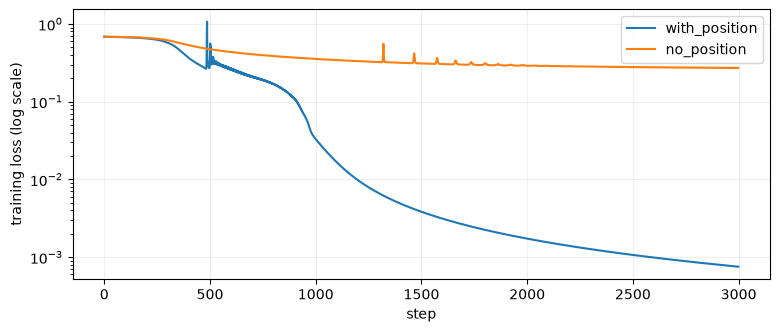

with_position  training loss 0.6849 → 0.0008
no_position    training loss 0.6874 → 0.2713


In [7]:
def train_model(use_position, steps=STEPS, learning_rate=LEARNING_RATE, seed=SEED):
    params = init_params(seed)
    initial = {k: v.copy() for k, v in params.items()}
    batch = batch_arrays(train)
    history = []
    for step in range(steps):
        loss, _, _, grads = forward_backward(params, batch, use_position)
        history.append(loss)
        for name in params:
            params[name] -= learning_rate * grads[name]
    return {"initial": initial, "trained": params, "loss_history": history}


models = {"with_position": train_model(True), "no_position": train_model(False)}

plt.figure(figsize=(9, 3.5))
for name, m in models.items():
    plt.plot(m["loss_history"], label=name)
plt.yscale("log")
plt.xlabel("step")
plt.ylabel("training loss (log scale)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()
for name, m in models.items():
    print(f"{name:14} training loss {m['loss_history'][0]:.4f} → {m['loss_history'][-1]:.4f}")

## 5. Results

Accuracy uses the threshold p ≥ 0.5. **Training** numbers are measured on the sequences the model learned
from (training performance); **test** numbers on 300 sequences it never saw.

In [8]:
def predict(params, dataset, use_position):
    _, z, a, _ = forward_backward(params, batch_arrays(dataset), use_position)
    return z, a


def accuracy_table(params, use_position):
    rows = {}
    for split, data in (("train", train), ("test", test)):
        z, _ = predict(params, data, use_position)
        correct = (z >= 0) == np.array([e["label"] == 1 for e in data])
        rows[split] = {"overall": float(correct.mean())}
        for c in CATEGORIES:
            idx = [i for i, e in enumerate(data) if e["category"] == c]
            rows[split][c] = float(correct[idx].mean())
    return rows


accuracy = {name: accuracy_table(m["trained"], name == "with_position") for name, m in models.items()}
table = pd.DataFrame({(name, split): accuracy[name][split] for name in accuracy for split in ("train", "test")})
table.columns = pd.MultiIndex.from_tuples([(n, "training performance" if s == "train" else "test") for n, s in table.columns])
table.round(3)

with_position               no_position       
              training performance test training performance   test
overall                        1.0  1.0                0.875  0.787
true_start                     1.0  1.0                0.880  0.830
broken_rbs                     1.0  1.0                1.000  1.000
no_rbs                         1.0  1.0                1.000  1.000
misplaced_rbs                  1.0  1.0                0.576  0.260

In [9]:
with_pos = accuracy["with_position"]["test"]["misplaced_rbs"]
without_pos = accuracy["no_position"]["test"]["misplaced_rbs"]
criterion = {
    "statement": "test accuracy on misplaced_rbs: with positions >= 0.90 and without positions <= 0.50",
    "with_position": with_pos, "no_position": without_pos,
    "holds": bool(with_pos >= 0.90 and without_pos <= 0.50),
}
print(f"misplaced_rbs, test: with positions {with_pos:.3f} (needs ≥ 0.90), without positions {without_pos:.3f} (needs ≤ 0.50)")
print("Prediction", "HOLDS" if criterion["holds"] else "FAILS")

misplaced_rbs, test: with positions 1.000 (needs ≥ 0.90), without positions 0.260 (needs ≤ 0.50)
Prediction HOLDS


### Why a model without positions cannot see *where* the RBS is

Without $P$, row $j$ of $X$ depends only on token $j$, not on where it is. Attention from `WXV` gives every
token a weight that depends only on the token, and $h$ is a weighted average: **shuffling the sequence does not
change $h$, so it cannot change $p$**. The next cell takes a true start and moves its RBS behind the start — a
misplaced RBS — and compares the two models.

In [10]:
original = next(e for e in test if e["category"] == "true_start")
moved = [c for c in original["tokens"] if c != RBS[0]]          # remove WXX WXX …
moved = moved + list(RBS)                                       # … and put it at the end, after the gene start
moved_target = moved.index(INITIATOR)
for name, m in models.items():
    use_position = name == "with_position"
    p_before = forward(m["trained"], original["tokens"], original["target"], use_position)["p"]
    p_after = forward(m["trained"], moved, moved_target, use_position)["p"]
    print(f"{name:14} p(true start): RBS in front {p_before:.3f} → RBS moved behind {p_after:.3f}")
print("\nbefore:", " ".join(original["tokens"]))
print("after: ", " ".join(moved))

with_position  p(true start): RBS in front 1.000 → RBS moved behind 0.000
no_position    p(true start): RBS in front 0.950 → RBS moved behind 0.950

before: XWV XVV WXX WXX XXY WXV WVY YWX XXY
after:  XWV XVV XXY WXV WVY YWX XXY WXX WXX


### Attention of the `WXV` token

One test example per category. Each heat map is the full attention matrix $A$ (row = the token that looks,
column = the token looked at); the framed row is the `WXV` row, the only one the classifier uses — the other
rows are computed but never trained.

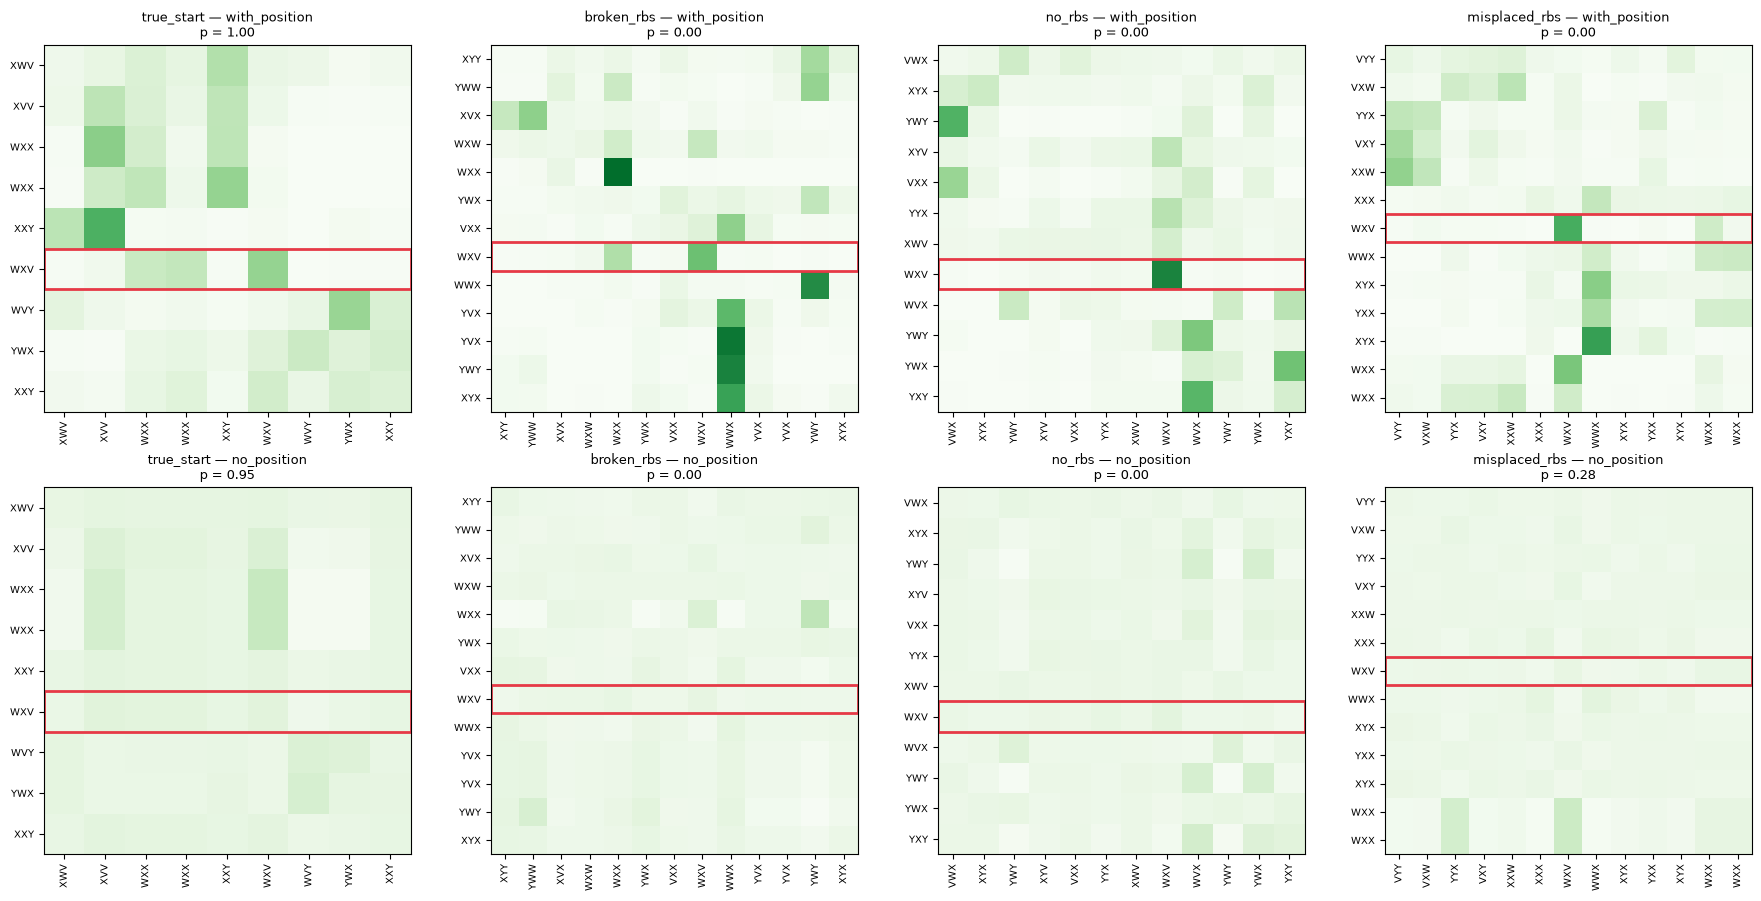

In [11]:
def plot_attention(ax, params, example, use_position, title):
    f = forward(params, example["tokens"], example["target"], use_position)
    ax.imshow(f["A"], cmap="Greens", vmin=0, vmax=1)
    ax.set_xticks(range(len(example["tokens"])), example["tokens"], rotation=90, fontsize=7)
    ax.set_yticks(range(len(example["tokens"])), example["tokens"], fontsize=7)
    t = example["target"]
    ax.add_patch(plt.Rectangle((-0.5, t - 0.5), len(example["tokens"]), 1, fill=False, ec="#e63946", lw=2))
    ax.set_title(f"{title}\np = {f['p']:.2f}", fontsize=9)


examples = [next(e for e in test if e["category"] == c) for c in CATEGORIES]
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for col, e in enumerate(examples):
    for row, name in enumerate(models):
        plot_attention(axes[row, col], models[name]["trained"], e, name == "with_position", f"{e['category']} — {name}")
fig.tight_layout()
plt.show()

### What came out (seed 42)

**The prediction holds.** On the 50 test sequences with a misplaced RBS:
- the model **with** positions is correct on all of them (1.000; the criterion needed ≥ 0.90);
- the model **without** positions is correct on only 26% (0.260; the criterion needed ≤ 0.50). That is worse
  than chance: it calls most of them true starts, because the tokens of a misplaced RBS are the same as those
  of a true start.

Other results:
- **The model with positions** reaches 100% on every category, in training and on the test set. One head with
  d = 4 is enough to learn "an intact RBS 2–5 positions to my left".
- **The model without positions** solves the categories where the *tokens* differ: broken RBS and no RBS are
  1.000 on test. It fails exactly where only the *arrangement* differs.
  - Its training performance on misplaced RBS (0.576) is higher than its test accuracy (0.260). It has
    memorised a few training sequences through their spacer codons, which does not transfer to new ones.
  - It also gives up some true starts (0.830 on test) to hedge against the misplaced ones: the two categories
    look the same to it.
- **The demonstration above** shows the mechanism directly. Moving the RBS behind the start changes the
  with-positions model from p = 1.00 to p = 0.00. The no-positions model stays at p = 0.95, because to it the
  two sequences are the same bag of tokens.

**Caveat — where the model looks.** The attention maps show where the `WXV` row puts its weight, and the
accuracy shows that the readout works. The maps alone do not prove *why* the classifier decides; the
controlled comparison (same data, same seed, positions on or off) is the evidence.

## 6. Export for Lab B

`mini-transcripts.json` contains the dataset, both models (initial and trained weights, loss history,
accuracies) and, for the parity check, the test logits and the `WXV` attention rows computed here. Lab B runs
its own JavaScript forward pass on the trained weights and compares.

In [12]:
def to_lists(params):
    return {k: np.asarray(v, dtype=float).tolist() for k, v in params.items()}     # full precision, for exact parity


parity = {}
for name, m in models.items():
    z, a = predict(m["trained"], test, name == "with_position")
    parity[name] = {"logits": z.tolist(), "attention": [a[i, :len(e["tokens"])].tolist() for i, e in enumerate(test)]}

payload = {
    "metadata": {
        "produced_by": NOTEBOOK,
        "function": forward_backward.__name__,
        "source": "\n\n".join(inspect.getsource(f) for f in (forward, forward_backward, train_model, make_mini_transcript)),
        "seed": SEED,
        "params": {"d": D, "max_len": MAX_LEN, "n_train": N_TRAIN, "n_test": N_TEST, "init_std": INIT_STD,
                   "learning_rate": LEARNING_RATE, "steps": STEPS, "categories": CATEGORIES, "category_p": CATEGORY_P},
        "generator_version": L.GENERATOR_VERSION,
        "created": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    },
    "vocabulary": VOCABULARY,
    "config": {"d": D, "max_len": MAX_LEN, "learning_rate": LEARNING_RATE, "steps": STEPS, "init_std": INIT_STD},
    "categories": CATEGORIES,
    "train": train,
    "test": test,
    "models": {name: {"initial": to_lists(m["initial"]), "trained": to_lists(m["trained"]),
                      "loss_history": m["loss_history"], "accuracy": accuracy[name]}
               for name, m in models.items()},
    "parity": parity,
    "criterion": criterion,
}
with open(OUTPUT_FILE, "w", encoding="utf-8") as f:
    json.dump(payload, f, separators=(",", ":"))
print(f"Saved {OUTPUT_FILE} ({os.path.getsize(OUTPUT_FILE) / 1e6:.2f} MB)")

Saved ../data/web/mini-transcripts.json (0.44 MB)
